# Clinical Models

Set `QUICK = True` for a fast run on a 5,000 patient sample.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
from IPython.display import Image, Markdown, display

In [2]:
from cardiac import config
from cardiac.tabular import train

QUICK = False
results = train.run(sample=5000 if QUICK else None, tune=not QUICK, cv_folds=3 if QUICK else 5)
results.drop(columns=['best_params'])

Start rows: 70,000
  - missing values: removed 0
  - duplicate records: removed 24
  - height outside [120, 220]: removed 53
  - weight outside [30, 200]: removed 7
  - ap_hi outside [70, 250]: removed 227
  - ap_lo outside [40, 150]: removed 1,015
  - bmi outside [12, 60]: removed 25
  - systolic <= diastolic: removed 88
Final rows: 68,561
Using 68,561 patients | positive rate 49.5%
Naive Bayes              CV AUC 0.784±0.004 | test acc 0.718 AUC 0.783 | 17s
Logistic Regression      CV AUC 0.791±0.003 | test acc 0.725 AUC 0.791 | 7s
k-Nearest Neighbours     CV AUC 0.796±0.005 | test acc 0.729 AUC 0.797 | 206s


C:\Users\LENOVO\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Random Forest            CV AUC 0.800±0.004 | test acc 0.731 AUC 0.802 | 483s
Hist Gradient Boosting   CV AUC 0.801±0.003 | test acc 0.733 AUC 0.803 | 50s


C:\Users\LENOVO\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


XGBoost                  CV AUC 0.802±0.003 | test acc 0.733 AUC 0.804 | 80s


c:\Users\LENOVO\anaconda3\envs\crenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Best by CV: XGBoost. Results written to D:\cardiac project\reports


,model,key,cv_roc_auc,cv_roc_auc_std,train_accuracy,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,seconds
0,XGBoost,xgboost,0.801576,0.003421,0.744220,0.733027,0.752221,0.686468,0.717842,0.803942,80.1
1,Hist Gradient Boosting,hist_gradient_boosting,0.801166,0.003308,0.740702,0.732590,0.750201,0.688827,0.718205,0.802690,50.2
2,Random Forest,random_forest,0.800153,0.003950,0.748377,0.730912,0.752695,0.679245,0.714086,0.802367,482.9
3,k-Nearest Neighbours,knn,0.796268,0.004579,0.735323,0.728870,0.753724,0.671285,0.710120,0.797374,197.4
4,Logistic Regression,logistic_regression,0.791390,0.003481,0.728213,0.725443,0.750789,0.666126,0.705928,0.791463,6.5
5,Naive Bayes,naive_bayes,0.783912,0.004419,0.721412,0.718297,0.769217,0.615124,0.683594,0.782625,16.6


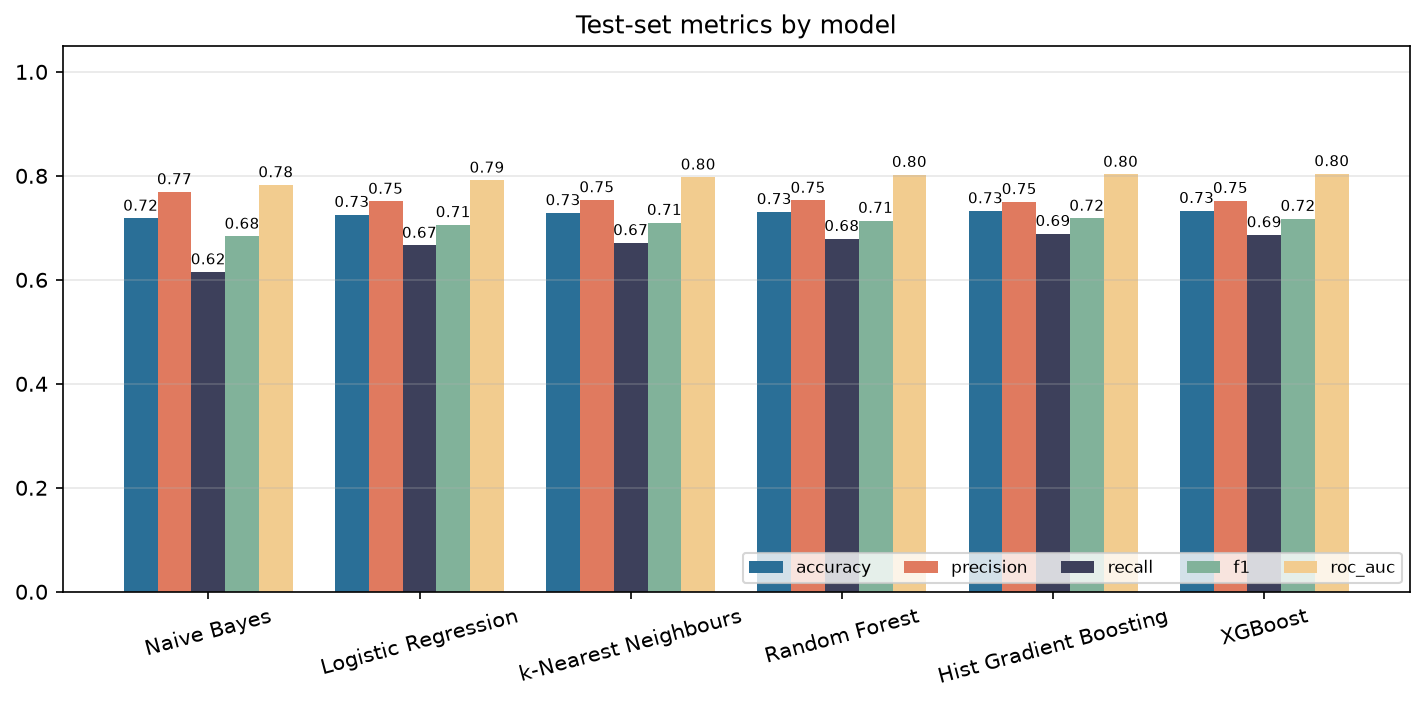

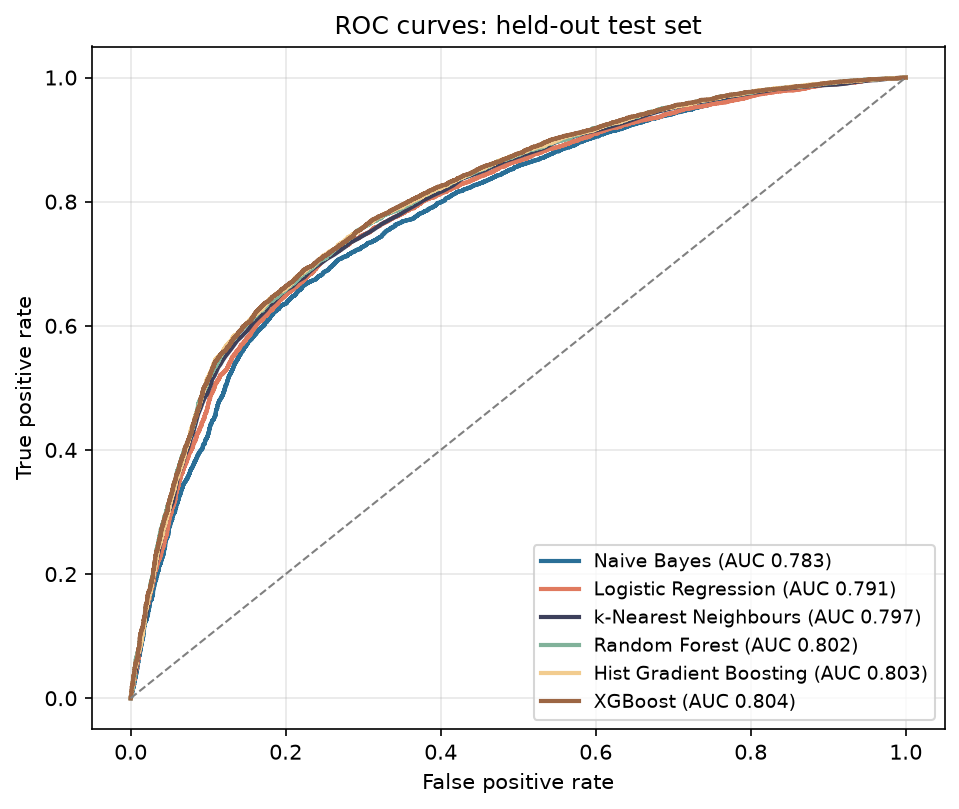

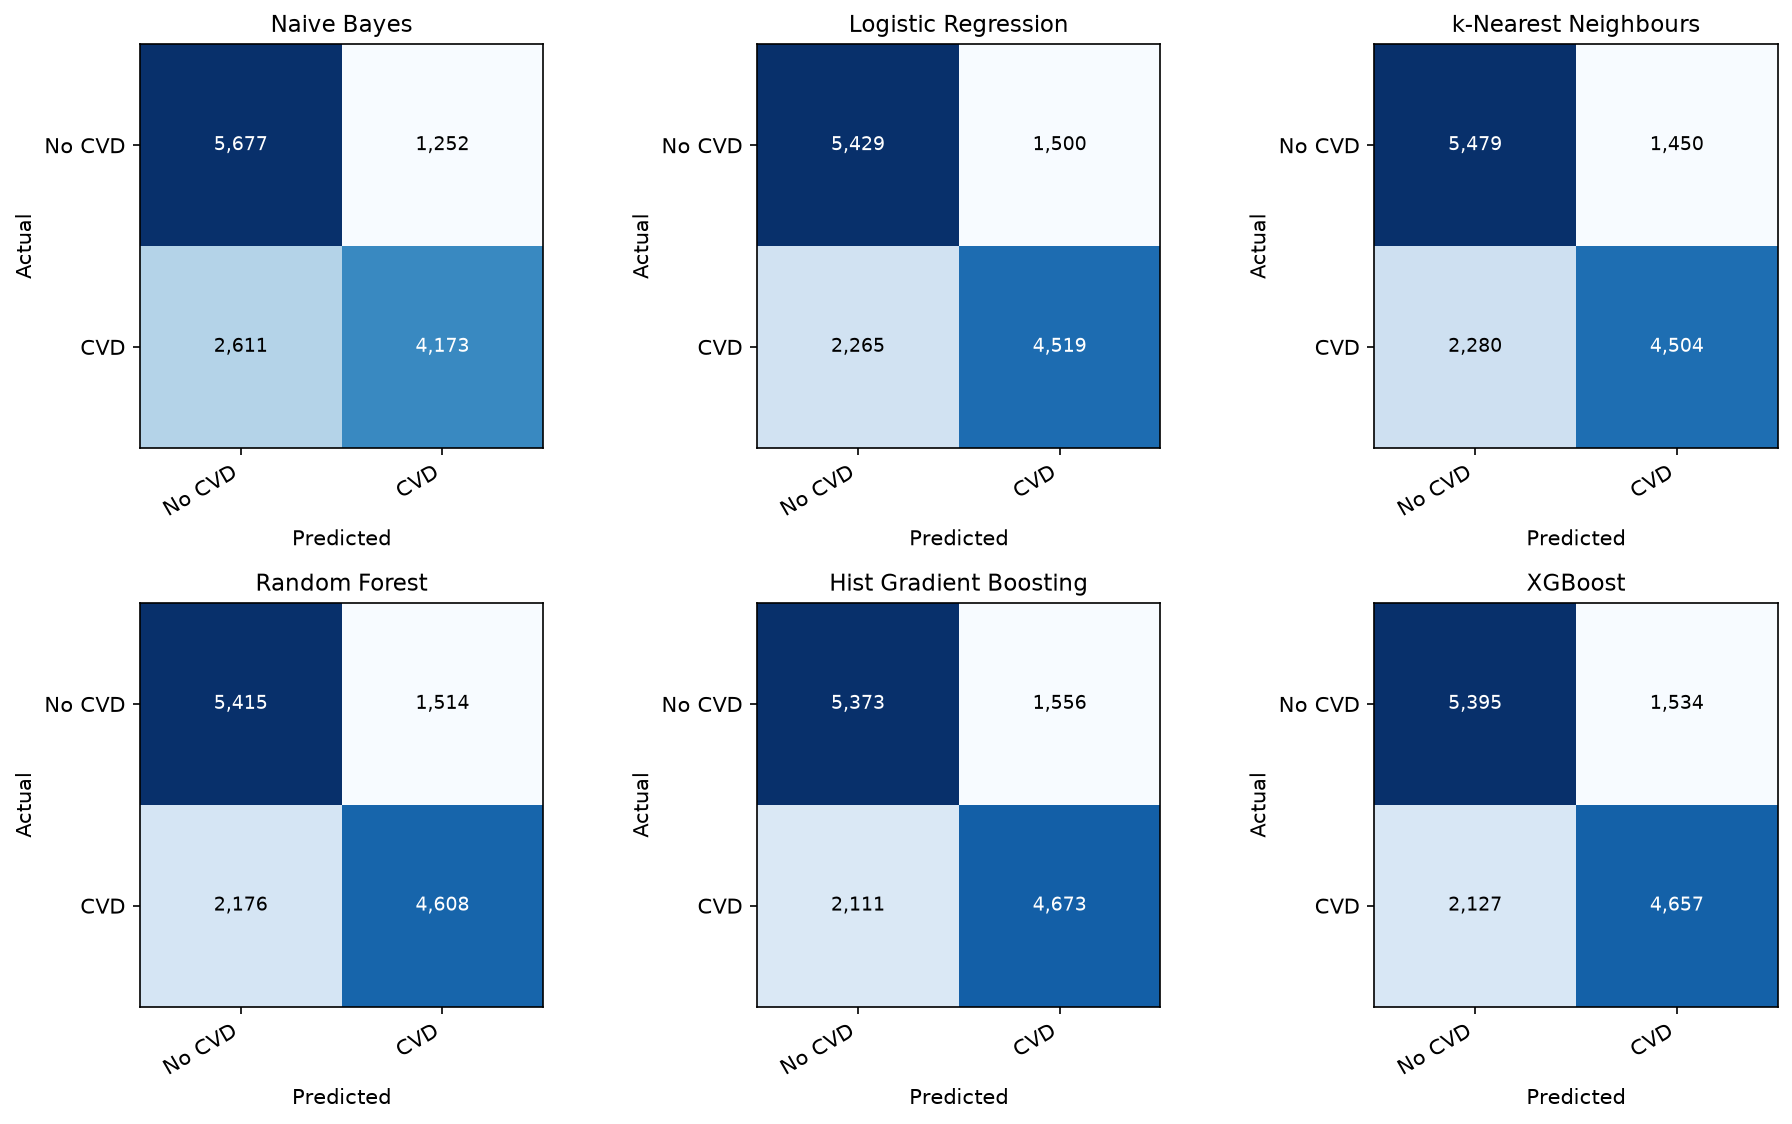

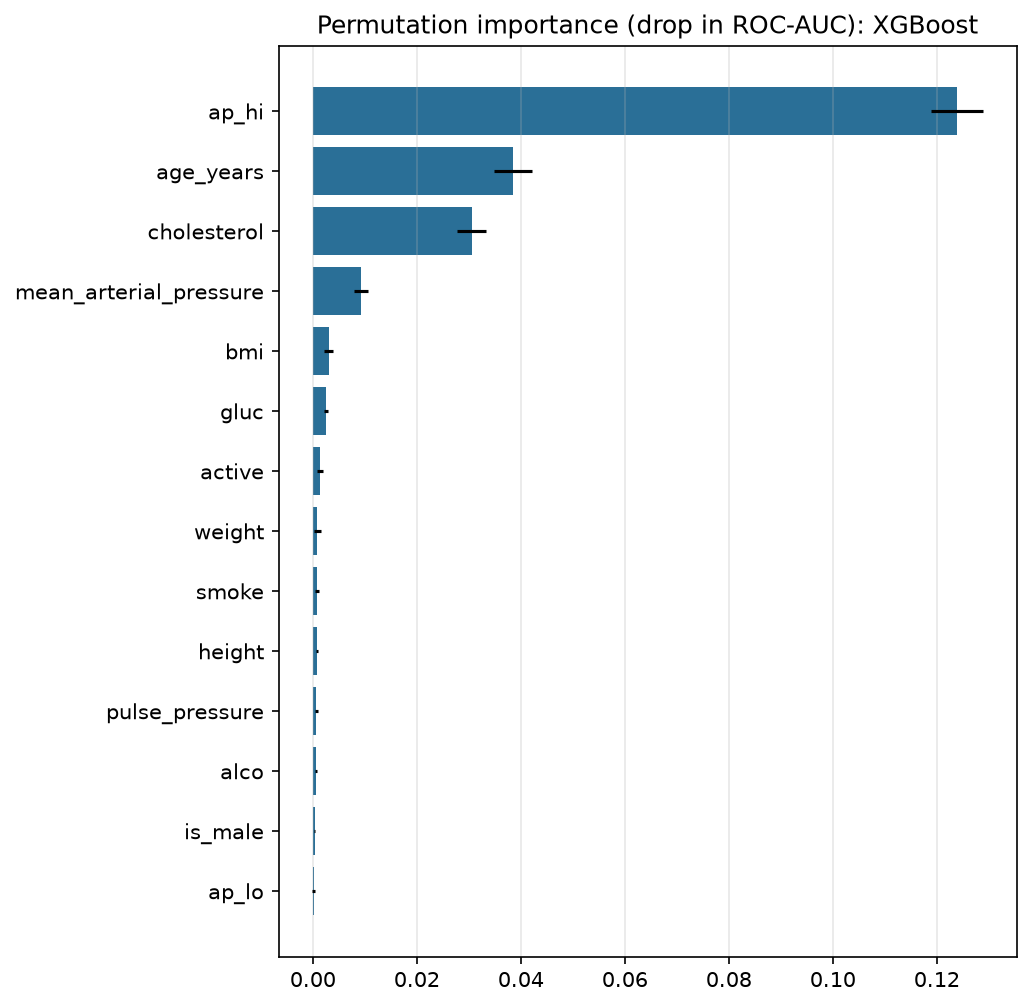

In [3]:
for f in ['tabular_metrics', 'tabular_roc', 'tabular_confusion', 'tabular_importance']:
    display(Image(filename=str(config.FIGURES_DIR / f'{f}.png')))